# Water Hyacinth Detection in Lake Victoria with PolSAR (OPDiff)

Step-by-step workflow from the paper
**"Mapping and Monitoring of Water Hyacinth in Lake Victoria Using Polarimetric Radar Data"**
([IEEE JSTARS, 2024](https://ieeexplore.ieee.org/document/10711204)).

The notebook compares a **reference** Sentinel-1 VV-VH acquisition with a **target** acquisition using the
**Optimization of Power Difference (OPDiff)** change detector. The smallest eigenvalue of the power
difference matrix is thresholded to flag water hyacinth, and the result is clipped to the lake outline and plotted.

**Steps**
1. Imports and configuration
2. Helper functions (data loading, filtering, change detector)
3. Load and filter the reference and target images
4. Run the OPDiff change detector
5. Threshold, mask to the lake, and plot

## 1. Imports

In [1]:
import os
import shutil
import warnings

import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
import rasterio.features
from rasterio.plot import plotting_extent
import scipy.linalg as ln
import spectral.io.envi as envi
from scipy import signal
from tqdm import tqdm

plt.close("all")
warnings.filterwarnings("ignore")

## 2. Configuration

Edit the paths and dates below. The data folder should contain one sub-folder per acquisition date
(e.g. `20171022/`), each holding the ENVI files `C11_<date>`, `C22_<date>`, `C12_real_<date>` and `C12_imag_<date>`
(`.hdr` + `.img`) exported from SNAP.

In [2]:
DATA_DIR = r"E:\WHH\Frame_1\4_Stack_Sorted"                                    # sorted SNAP output, one folder per date
LAKE_SHP = r"E:\WHH\Frame_1\4_Stack_Sorted\lake_victoria_2\lake_victoria_2.shp"  # lake outline

REF_DATE    = "20171022"   # reference (clear-water) acquisition
TARGET_DATE = "20181228"   # acquisition to test for water hyacinth

WIN       = (7, 7)         # boxcar multilook window (rows, cols)
THRESHOLD = 0.005          # detection threshold on the smallest eigenvalue

## 3. Helper functions

### 3.1 (Optional) Sort the SNAP output
Run this **only the first time**, if the SNAP stacks (`*.data` folders) have not been sorted yet.
It copies the coregistered bands into one folder per date and renames them to `YYYYMMDD`.

In [3]:
MONTHS = {"Jan": "01", "Feb": "02", "Mar": "03", "Apr": "04", "May": "05", "Jun": "06",
          "Jul": "07", "Aug": "08", "Sep": "09", "Oct": "10", "Nov": "11", "Dec": "12"}


def convert_month_to_number(string):
    # Convert a three-letter month name (e.g. 'Oct') to a two-digit string ('10').
    return MONTHS[string]


def sort_files_snap(path_pre, path):
    # Copy SNAP coregistered bands into one folder per date and rename them to YYYYMMDD.
    #   path_pre : folder with the SNAP stack (.data / .dim)
    #   path     : output folder for the sorted files
    list_names_all = sorted(os.listdir(path_pre))
    list_dates = [n[:-5] for n in list_names_all if n.endswith(".data")]

    for date_dir in list_dates:
        os.makedirs(os.path.join(path, date_dir), exist_ok=True)

        from_dir = os.path.join(path_pre, date_dir + ".data")
        to_dir = os.path.join(path, date_dir)

        # the last entry of the .data folder is skipped, as in the original script
        for name in sorted(os.listdir(from_dir))[:-1]:
            shutil.copy2(os.path.join(from_dir, name), os.path.join(to_dir, name))

        for name in sorted(os.listdir(to_dir)):
            full = os.path.join(to_dir, name)

            if len(name) < 15 or "mst" in name:       # drop short names and master-image files
                os.remove(full)
                continue

            for k in range(4):                          # keep only the coregistered slave bands
                tag = f"slv{k}_"
                if tag in name:
                    clean = name.replace(tag, "")
                    ext = clean[-4:]
                    date_str = clean[-13:-4]            # e.g. '22Oct2017'
                    new_date = date_str[-4:] + convert_month_to_number(date_str[2:5]) + date_str[:2]
                    new_name = clean[:-13] + new_date + ext
                    new_full = os.path.join(to_dir, new_name)
                    if not os.path.exists(new_full):
                        os.rename(full, new_full)
    return list_dates


# Uncomment to run once:
# sort_files_snap(r"E:\WHH\Frame_1\3_Stack", DATA_DIR)

### 3.2 Reading the data
`open_envi_image` reads one ENVI band, and `load_one_date_dual` assembles the 2x2 dual-pol covariance matrix
elements (C11 = VV power, C22 = VH power, C12 = VV·VH* cross-correlation, stored as real and imaginary parts).

In [4]:
def open_envi_image(filename):
    # Read an ENVI band (filename without extension) using the size and dtype in its .hdr file.
    lib = envi.open(filename + ".hdr")
    shape = (lib.ncols, lib.nrows)
    dtype = lib.dtype
    img = np.fromfile(filename + ".img", dtype=dtype)
    return img.reshape(shape, order="F").astype(dtype)


def load_one_date_dual(folder, date):
    # Load the dual-pol covariance matrix elements (C11, C22, C12) for one acquisition.
    c11 = open_envi_image(os.path.join(folder, "C11_" + date))
    c22 = open_envi_image(os.path.join(folder, "C22_" + date))
    c12_re = open_envi_image(os.path.join(folder, "C12_real_" + date))
    c12_im = open_envi_image(os.path.join(folder, "C12_imag_" + date))
    c12 = c12_re + 1j * c12_im          # off-diagonal term is complex
    del c12_re, c12_im
    return c11, c22, c12

### 3.3 Boxcar multilooking
Averages each covariance element over a `win` window to reduce speckle before change detection.

In [5]:
def boxcar_pol_filter_dual(c11_in, c22_in, c12_in, win):
    # Apply a boxcar (moving average) filter to the covariance matrix elements.
    kernel = np.ones((int(win[0]), int(win[1])), np.float32) / (win[0] * win[1])
    kw = dict(mode="same", boundary="fill", fillvalue=0)
    return (signal.convolve2d(c11_in, kernel, **kw),
            signal.convolve2d(c22_in, kernel, **kw),
            signal.convolve2d(c12_in, kernel, **kw))

### 3.4 OPDiff change detector
For each pixel, the covariance matrices of the target (**A**) and reference (**B**) are compared:

- **Power difference** `D = A - B`: its eigenvalues (`dif1` largest, `dif2` smallest) and eigenvector alpha angles are stored.
  The **smallest eigenvalue (`dif2`)** is the quantity thresholded in this study. It rejects false alarms from polarized
  scattering (e.g. waves and wind) and keeps the unpolarized scattering contribution.
- **Power ratio** `B⁻¹A`: the largest eigenvalue (`rat1`) and the inverse of the smallest (`rat2`) are also computed.

In [7]:
def opt_change_det_dual(c11_a, c22_a, c12_a, c11_b, c22_b, c12_b):
    # Optimization of Power Difference (OPDiff) for dual-pol data.
    #   a = target image, b = reference image
    # Returns rat1, rat2, dif1, dif2, alpha1, alpha2 (same shape as the inputs).
    dima, dimr = np.shape(c11_a)

    Ta = np.zeros((2, 2), dtype=np.complex64)
    Tb = np.zeros((2, 2), dtype=np.complex64)

    rat1 = np.zeros((dima, dimr)); rat2 = np.zeros((dima, dimr))
    dif1 = np.zeros((dima, dimr)); dif2 = np.zeros((dima, dimr))
    alpha1 = np.zeros((dima, dimr)); alpha2 = np.zeros((dima, dimr))

    for i in tqdm(range(0, dima - 1), desc="OPDiff rows"):
        for ii in range(0, dimr - 1):
            # small offset keeps the matrices invertible
            Ta[0, 0] = c11_a[i, ii] + 1e-6
            Ta[1, 1] = c22_a[i, ii] + 1e-6
            Ta[0, 1] = c12_a[i, ii]
            Ta[1, 0] = np.conj(Ta[0, 1])

            Tb[0, 0] = c11_b[i, ii] + 1e-6
            Tb[1, 1] = c22_b[i, ii] + 1e-6
            Tb[0, 1] = c12_b[i, ii]
            Tb[1, 0] = np.conj(Tb[0, 1])

            # Power difference (Hermitian -> eigh returns ascending eigenvalues)
            d2, v2 = np.linalg.eigh(Ta - Tb)
            dif1[i, ii] = d2[1]
            dif2[i, ii] = d2[0]

            # Alpha angles
            alpha1[i, ii] = np.arccos(np.abs(v2[0, 1]))
            alpha2[i, ii] = np.arccos(np.abs(v2[0, 0]))

            # Power ratio
            d1, _ = ln.eig(np.matmul(ln.inv(Tb), Ta))
            rat1[i, ii] = np.abs(np.max(d1))
            rat2[i, ii] = np.abs(1.0 / np.min(d1))

    return rat1, rat2, dif1, dif2, alpha1, alpha2

## 4. Load and filter the images

### 4.1 Reference image

In [8]:
folder_ref = os.path.join(DATA_DIR, REF_DATE)
c11, c22, c12 = load_one_date_dual(folder_ref, REF_DATE)

print("Applying boxcar filter to reference image")
C11_ref, C22_ref, C12_ref = boxcar_pol_filter_dual(c11, c22, c12, WIN)
del c11, c22, c12
print("Image size (cols x rows):", C11_ref.shape)

Applying boxcar filter to reference image
Image size (cols x rows): (3437, 2557)


### 4.2 Target image

In [9]:
folder_tgt = os.path.join(DATA_DIR, TARGET_DATE)
c11, c22, c12 = load_one_date_dual(folder_tgt, TARGET_DATE)

print("Applying boxcar filter to target image")
C11_tgt, C22_tgt, C12_tgt = boxcar_pol_filter_dual(c11, c22, c12, WIN)
del c11, c22, c12

Applying boxcar filter to target image


## 5. Run the change detector
This loops over every pixel and can take a while on a full scene. A progress bar shows how many rows remain.
##### note: an updated code will be inserted with a faster processing 

In [10]:
rat1, rat2, dif1, dif2, alpha1, alpha2 = opt_change_det_dual(
    C11_tgt, C22_tgt, C12_tgt,
    C11_ref, C22_ref, C12_ref,
)
del C11_tgt, C22_tgt, C12_tgt

OPDiff rows: 100%|█████████████████████████████████████████████████████████████████| 3436/3436 [13:25<00:00,  4.27it/s]


## 6. Threshold, mask to the lake, and plot

- **Threshold:** pixels where the smallest eigenvalue (`dif2`) exceeds `THRESHOLD` are flagged as water hyacinth. The threshold value was assessed on multiple images using optical images as reference, and gave the highest accuracy. Other thresholding methods can be applied.
- **Georeferencing:** the affine transform is read from the SNAP output so the result lines up with the lake outline.
- **Transpose:** `open_envi_image` returns arrays as (cols, rows), so the detection is transposed back to (rows, cols)
  to match the raster. Remove the transpose if your output looks rotated.
- **Mask:** pixels outside the lake outline are set to NaN. Nothing is written to disk.

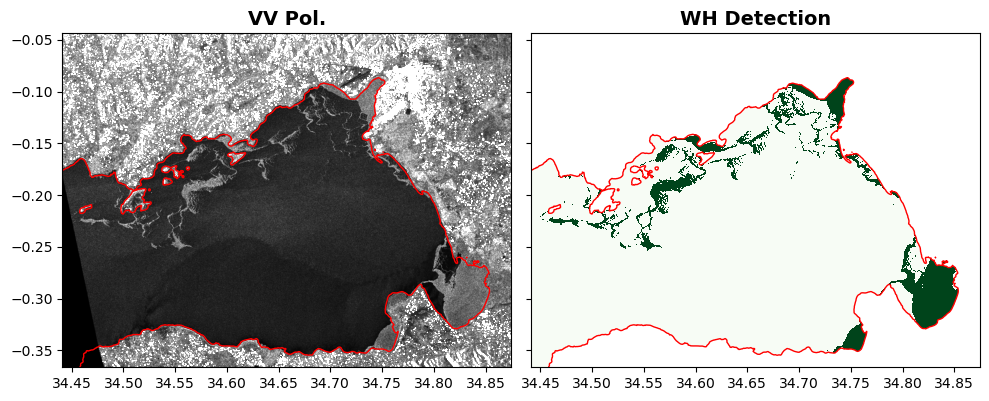

In [11]:
# Threshold detection
wh_det = np.transpose(dif2 > THRESHOLD).astype("int8")

# Georeferencing from the source raster
src = rasterio.open(os.path.join(DATA_DIR, TARGET_DATE, f"C11_{TARGET_DATE}.img"))
transform = src.transform
extent = plotting_extent(wh_det, transform)          # (left, right, bottom, top)

# Lake mask (in memory)
lake = gpd.read_file(LAKE_SHP).to_crs("EPSG:4326")
inside = rasterio.features.geometry_mask(
    lake.geometry, out_shape=wh_det.shape, transform=transform, invert=True
)
wh_det_clipped = np.where(inside, wh_det, np.nan)    # NaN outside the lake -> blank

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

vv = src.read(1)
ax1.imshow(vv, cmap="gray", vmin=0, vmax=2 * np.nanmean(vv), extent=extent)
lake.plot(ax=ax1, facecolor="none", edgecolor="r")
ax1.set_title("VV Pol.", fontsize=14, fontweight="bold")

ax2.imshow(wh_det_clipped, cmap="Greens", extent=extent, interpolation="none")
lake.plot(ax=ax2, facecolor="none", edgecolor="r")
ax2.set_title("WH Detection", fontsize=14, fontweight="bold")

ax1.set_xlim(extent[0], extent[1])
ax1.set_ylim(extent[2], extent[3])

plt.tight_layout()
plt.show()

## 7. (Optional) Detected area
Rough estimate of detected water hyacinth area, assuming a known pixel area (set `PIXEL_AREA_KM2` for your
multilooked pixel size).

In [14]:
PIXEL_AREA_KM2 = 0.0004 

n_pixels = int(np.nansum(wh_det_clipped))
print(f"Detected pixels inside lake: {n_pixels}")
if PIXEL_AREA_KM2:
    print(f"Approximate area: {n_pixels * PIXEL_AREA_KM2:.1f} km2")

Detected pixels inside lake: 433488
Approximate area: 173.4 km2
